Tehtävä 9
Tee noin 20 sekunnin mittaukset kolmella saatavilla olevalla sensorilla, esimerkiksi kiihtyvyysanturilla, magnetometrillä ja GPS:llä.

a) Laske peräkkäisten havaintojen aikavälit ja tutki, ovatko ne vakioita.

b) Laske koko mittauksen keskimääräinen näytteenottotaajuus  
fˉ<sub>s</sub>=(N−1)/(t<sub>n-1</sub>−t<sub>0</sub>), missä N on havaintojen määrä.

c) Laske yksittäisiä aikavälejä vastaavat taajuudet f<sub>i</sub>=1/(t<sub>i+1</sub>−t<sub>i</sub>). Määritä niiden pienin ja suurin arvo. Tarkista ensin, ovatko kaikki aikavälit positiivisia, ja selvitä mahdolliset poikkeamat.

d) Piirrä aikaväleistä laskettujen taajuuksien histogrammit eri sensoreille. Vertaa tuloksia.



In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#a)
acc = pd.read_csv('./Data/Accelerometer.csv')
mg = pd.read_csv('./Data/Magnetometer.csv')
gps = pd.read_csv('./Data/Location.csv')

#mittauksien määrä
acc_measures = len(acc)
mg_measures = len(mg)
gps_measures = len(gps)

#mittauksien aikaero edelliseen
acc['aikavaliAcc'] = acc['Time (s)'].diff()
mg['aikavaliMg'] = mg['Time (s)'].diff()
gps['aikavaliGps'] = gps['Time (s)'].diff()

#Mittauksien keskiarvot
acc_avg = acc['aikavaliAcc'].mean()
mg_avg = mg['aikavaliMg'].mean()
gps_avg = gps['aikavaliGps'].mean()
print(acc_avg, mg_avg, gps_avg)

# print(acc['aikavaliAcc'].to_string())
# print(mg['aikavaliMg'].to_string())
# print(gps['aikavaliGps'].to_string())
print(acc)
print(mg)
print(gps)

#Kiihtyvyys (0.00202) ja magneettisuus (0.01010) mittaukset on käytännössä vakioita
#gps mittaus n. sekunnin välein mutta niissä oli 0.06s heittoja

0.002020661715482026 0.01010377885394402 1.0947953300555555
       Time (s)  Acceleration x (m/s^2)  Acceleration y (m/s^2)  \
0      0.254107               -2.281674                9.421483   
1      0.256123               -2.346318                9.409512   
2      0.258137               -2.351106                9.407118   
3      0.260151               -2.377442                9.390358   
4      0.262166               -2.394202                9.380781   
...         ...                     ...                     ...   
9788  20.032351                0.014365                7.719205   
9789  20.034370                0.004788                7.714417   
9790  20.036389                0.002394                7.723994   
9791  20.038407               -0.007183                7.731176   
9792  20.040426               -0.014365                7.733571   

      Acceleration z (m/s^2)  aikavaliAcc  
0                   1.151611          NaN  
1                   1.177947     0.002016  
2  

In [21]:
#b)
taajuusgps = (len(gps) - 1) / (gps['Time (s)'].iloc[-1] - gps['Time (s)'].iloc[0])
print(taajuusgps, 'Hz')
#=(18-1)/(19,7629-0,0566)

taajuusacc = (len(acc) - 1) / (acc['Time (s)'].iloc[-1] - acc['Time (s)'].iloc[0])
print(taajuusacc, 'Hz')
#=(9792-1)/(20.040-0.254)

taajuusmg = (len(mg) - 1) / (mg['Time (s)'].iloc[-1] - mg['Time (s)'].iloc[0])
print(taajuusmg, 'Hz')
#=(1965-1)/(20,0385-0,1845)

0.9134127380222337 Hz
494.8873887886035 Hz
98.97287088876148 Hz


In [22]:
# c) Yksittäisiä aikavälejä vastaavat taajuudet

sensorit = {
    'Kiihtyvyysanturi': (acc, 'aikavaliAcc'),
    'Magnetometri': (mg, 'aikavaliMg'),
    'GPS': (gps, 'aikavaliGps')
}

taajuudet = {}

for nimi, (data, aikavali_sarake) in sensorit.items():
    aikavalit = data[aikavali_sarake].dropna()

    # Tarkistetaan aikavälien positiivisuus
    poikkeamat = aikavalit[aikavalit <= 0]

    if len(poikkeamat) > 0:
        print(f'{nimi}: löytyi {len(poikkeamat)} epäkelpoa aikaväliä.')
        aikavalit = aikavalit[aikavalit > 0]
    else:
        print(f'{nimi}: kaikki aikavälit ovat positiivisia.')

    f = 1 / aikavalit
    taajuudet[nimi] = f

    print(f'{nimi}:')
    print(f'  pienin taajuus = {f.min():.3f} Hz')
    print(f'  suurin taajuus = {f.max():.3f} Hz')
    print(f'  keskimääräinen taajuus = {f.mean():.3f} Hz')

Kiihtyvyysanturi: kaikki aikavälit ovat positiivisia.
Kiihtyvyysanturi:
  pienin taajuus = 322.893 Hz
  suurin taajuus = 988.142 Hz
  keskimääräinen taajuus = 494.959 Hz
Magnetometri: kaikki aikavälit ovat positiivisia.
Magnetometri:
  pienin taajuus = 86.964 Hz
  suurin taajuus = 111.826 Hz
  keskimääräinen taajuus = 98.979 Hz
GPS: kaikki aikavälit ovat positiivisia.
GPS:
  pienin taajuus = 0.371 Hz
  suurin taajuus = 3.388 Hz
  keskimääräinen taajuus = 1.075 Hz


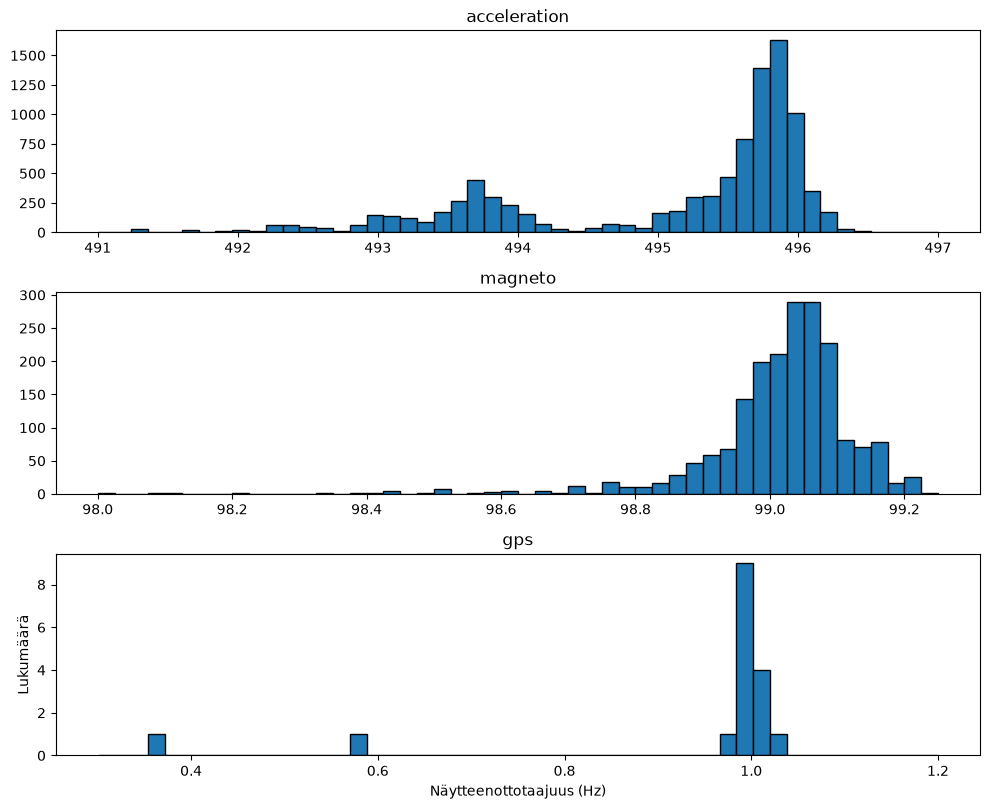

In [51]:
acc['taajuus'] = 1 / acc['aikavaliAcc']
mg['taajuus'] = 1 / mg['aikavaliMg']
gps['taajuus'] = 1 / gps['aikavaliGps']

fig, axs = plt.subplots(3, 1, figsize=(10, 8))

axs[0].hist(acc['taajuus'], bins=50, range=(491, 497), edgecolor='black')
axs[0].set_title("acceleration")

axs[1].hist(mg['taajuus'], bins=50, range=(98, 99.25), edgecolor='black')
axs[1].set_title("magneto")

axs[2].hist(gps['taajuus'], bins=50, range=(0.3, 1.2), edgecolor='black')
axs[2].set_title("gps")

plt.tight_layout()


plt.xlabel("Näytteenottotaajuus (Hz)")
plt.ylabel("Lukumäärä")
plt.show()